In [79]:
import pandas as pd


In [80]:
df = pd.read_csv('dados_tratados.csv')

In [81]:
df.head()

,titulo,descricao,ocupacao,tarefa
0,0101-05 Oficial General da Aeronáutica - Briga...,"As funções deste grupo consistem em manter, cu...",10105,Abstrata
1,0101-10 Oficial General do Exército - General-...,"As funções deste grupo consistem em manter, cu...",10110,Abstrata
2,0101-15 Oficial General da Marinha - Almirante...,"As funções deste grupo consistem em manter, cu...",10115,Abstrata
3,0102-05 Oficial da Aeronáutica - Capitão; Coro...,Estão compreendidas nesta família ocupacional ...,10205,Abstrata
4,0102-10 Oficial do Exército - Capitão; Coronel...,Estão compreendidas nesta família ocupacional ...,10210,Abstrata


In [82]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2741 entries, 0 to 2740
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   titulo     2741 non-null   str  
 1   descricao  2741 non-null   str  
 2   ocupacao   2741 non-null   int64
 3   tarefa     2741 non-null   str  
dtypes: int64(1), str(3)
memory usage: 85.8 KB


In [83]:
%pip install unidecode nltk

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [84]:
import nltk
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]

True

Criando bag of words

In [85]:
from sklearn.feature_extraction.text import CountVectorizer
vetorizar = CountVectorizer(lowercase=False, max_features=50)
bag_of_words = vetorizar.fit_transform(df.descricao)
print(bag_of_words.shape)

(2741, 50)


In [86]:
matriz_esparsa_avaliacoes = pd.DataFrame.sparse.from_spmatrix(bag_of_words, columns=vetorizar.get_feature_names_out())
matriz_esparsa_avaliacoes

,Podem,Preparam,Realizam,Trabalham,ambiental,ambiente,ao,as,atividades,clientes,...,qualidade,realizam,recursos,saúde,segurança,serviços,sistemas,trabalho,técnicos,área
0,0,0,0,0,0,0,0,2,0,0,...,0,0,0,0,1,0,0,0,0,1
1,0,0,0,0,0,0,0,2,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,0,0,0,0,0,0,2,0,0,...,0,0,0,0,1,0,0,0,0,1
3,0,0,0,0,0,0,0,3,0,0,...,0,0,0,0,1,0,0,0,0,0
4,0,0,0,0,0,0,0,3,0,0,...,0,0,0,0,1,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2736,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2737,0,0,1,1,1,0,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
2738,0,0,0,0,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,0,0
2739,0,0,1,0,0,1,1,0,0,0,...,1,0,0,0,1,2,1,0,1,0


In [87]:
from sklearn.model_selection import train_test_split

x_treino, x_teste, y_treino, y_teste = train_test_split(bag_of_words, df.tarefa)

Primeira regressão para a bag of words

In [88]:
# A função multiclass não é mais usada
from sklearn.linear_model import LogisticRegression

regressao_multinomial = LogisticRegression(max_iter=1000)
regressao_multinomial.fit(x_treino, y_treino)
acuracia = regressao_multinomial.score(x_teste, y_teste)
print(f'Fazendo o primeiro teste para essa regressão multinomial temos a acuracia de: {acuracia * 100:.2f}%')

Fazendo o primeiro teste para essa regressão multinomial temos a acuracia de: 74.93%


In [89]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Primeira nuvem de palavras, sem tratamento nenhum

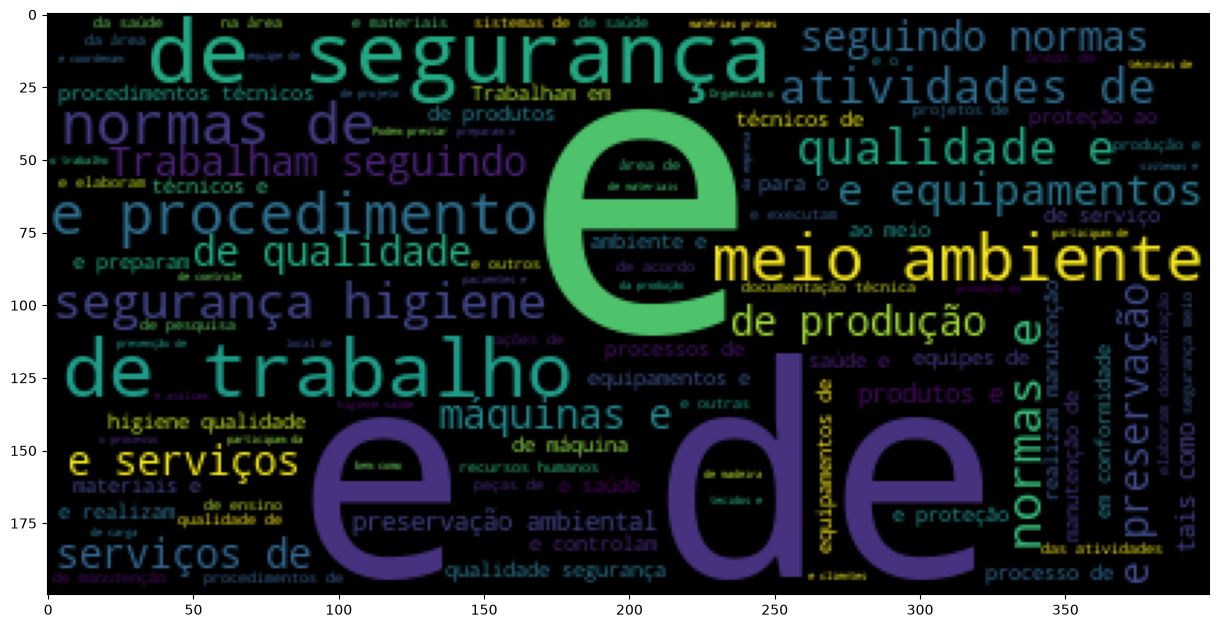

In [90]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

todas_palavras = [texto for texto in df.descricao]
todas_palavras = ' '.join([texto for texto in df.descricao])

nuvem_palavras = WordCloud().generate(todas_palavras)

plt.figure(figsize=(15, 10))
plt.imshow(nuvem_palavras)

In [91]:
nltk.download('all')

[nltk_data] Downloading collection 'all'
[nltk_data]    | 
[nltk_data]    | Downloading package abc to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package abc is already up-to-date!
[nltk_data]    | Downloading package alpino to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package alpino is already up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger is already up-
[nltk_data]    |       to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_eng to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]    |   Package averaged_perceptron_tagger_eng is already
[nltk_data]    |       up-to-date!
[nltk_data]    | Downloading package averaged_perceptron_tagger_ru to
[nltk_data]    |     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]

True

In [92]:
# Download specific NLTK data needed for RSLP stemmer
import nltk
nltk.download('stopwords')
nltk.download('rslp')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package rslp to
[nltk_data]     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]   Package rslp is already up-to-date!
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\ECO\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [93]:
import unidecode
import nltk
from nltk import tokenize

palavras_irrelevantes = nltk.corpus.stopwords.words('portuguese')
token_pontuacao = tokenize.WordPunctTokenizer()
stemmer = nltk.RSLPStemmer()

def processar_avaliacao(avaliacao):
  # Passo 1
  tokens = token_pontuacao.tokenize(avaliacao)

  # Passo 2
  frase_processada = [palavra for palavra in tokens if palavra.lower not in palavras_irrelevantes]

  # Passo 3
  frase_processada = [palavra for palavra in frase_processada if palavra.isalpha()]

  # Passo 4
  frase_processada = [unidecode.unidecode(palavra) for palavra in frase_processada]

  # Passo  5
  frase_processada = [stemmer.stem(palavra) for palavra in frase_processada]

  return ' '.join(frase_processada)

In [94]:
def nuvem_palavras(texto, coluna_texto, descricao):
    texto_descricao = texto.query(f'descricao == "{descricao}"')[coluna_texto]

    texto_unido = ' '.join(texto_descricao)
    nuvem_palavras = WordCloud(width=800, height=500, collocations=False)
    nuvem_palavras.generate(texto_unido)
    plt.figure(figsize=(15, 10))
    plt.imshow(nuvem_palavras, interpolation='bilinear')
    plt.axis('off')
    plt.show()

In [95]:
token_espaço = tokenize.WhitespaceTokenizer()
token_frase = token_espaço.tokenize(todas_palavras)
frequencia = nltk.FreqDist(token_frase)
frequencia.most_common(10)

[('e', 18057),
 ('de', 13332),
 ('a', 2166),
 ('em', 1980),
 ('para', 1633),
 ('o', 1609),
 ('da', 1554),
 ('do', 1167),
 ('atividades', 990),
 ('normas', 850)]

In [96]:
palavras_irrelevantes = nltk.corpus.stopwords.words('portuguese')

In [97]:
def classificar_texto(texto, coluna_texto, coluna_classificacao):
    vetorizar = CountVectorizer(lowercase=False, max_features=50)
    bag_of_words = vetorizar.fit_transform(texto[coluna_texto])
    X_treino, X_teste, y_treino, y_teste = train_test_split(bag_of_words, texto[coluna_classificacao], random_state=4978)
    regressao_logistica = LogisticRegression()
    regressao_logistica.fit(X_treino, y_treino)
    acuracia = regressao_logistica.score(X_teste, y_teste)
    return print(f"Acurácia do modelo com '{coluna_texto}': {acuracia * 100:.2f}%")

In [98]:
frase_processada = []

for descricao in df.descricao:
    palavras_texto = token_espaço.tokenize(descricao)
    nova_frase = [palavra for palavra in palavras_texto if palavra not in palavras_irrelevantes]
    frase_processada.append(' '.join(nova_frase))
  
df['tratamento_1'] = frase_processada

In [99]:
classificar_texto(df, 'tratamento_1', 'tarefa')

Acurácia do modelo com 'tratamento_1': 73.76%


In [100]:
frase_processada = []

for descricao in df['tratamento_1']:
  palavras_texto = token_pontuacao.tokenize(descricao)
  nova_frase = [palavra for palavra in palavras_texto if palavra.isalpha() and palavra not in palavras_irrelevantes]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_2'] = frase_processada

In [101]:
classificar_texto(df, 'tratamento_2', 'tarefa')

Acurácia do modelo com 'tratamento_2': 73.76%


In [102]:
import seaborn as sns

def grafico_frequencia(texto, coluna_texto, quantidade):
    todas_palavras = ' '.join([texto for texto in texto[coluna_texto]])
    token_espaco = tokenize.WhitespaceTokenizer()
    frequencia = nltk.FreqDist(token_espaco.tokenize(todas_palavras))
    df_frequencia = pd.DataFrame({"Palavra": list(frequencia.keys()),
                                  "Frequência": list(frequencia.values())})
    df_frequencia = df_frequencia.nlargest(columns="Frequência", n=quantidade)

    plt.figure(figsize=(20,6))

    ax = sns.barplot(data=df_frequencia, x="Palavra", y ="Frequência", hue='Palavra', palette=sns.color_palette("mako", n_colors=quantidade))

    ax.set(ylabel="Contagem")
    plt.show()

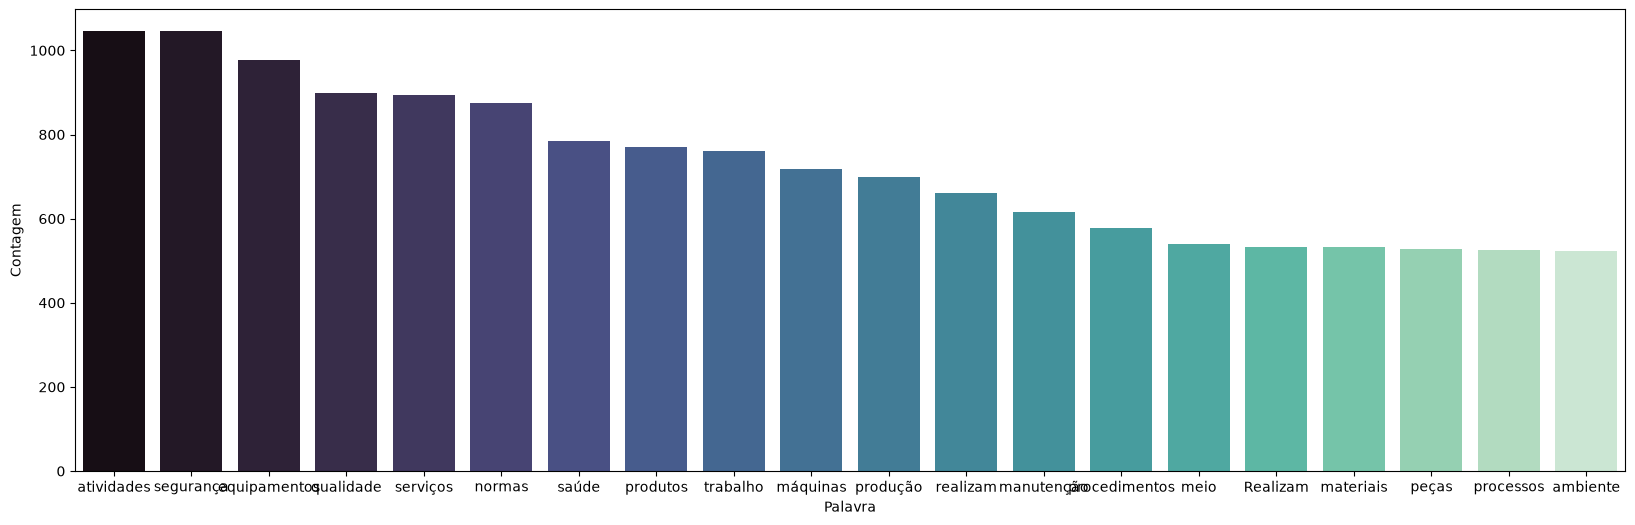

In [103]:
grafico_frequencia(df, 'tratamento_2', 20)

In [104]:
sem_acentos = [unidecode.unidecode(texto) for texto in df['tratamento_2']]
stopwords_sem_acento = [unidecode.unidecode(texto) for texto in palavras_irrelevantes]

In [105]:
df['tratamento_3'] = sem_acentos
frase_processada = []

for descricao in df['tratamento_3']:
  palavras_texto = token_pontuacao.tokenize(descricao)
  nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_3'] = frase_processada

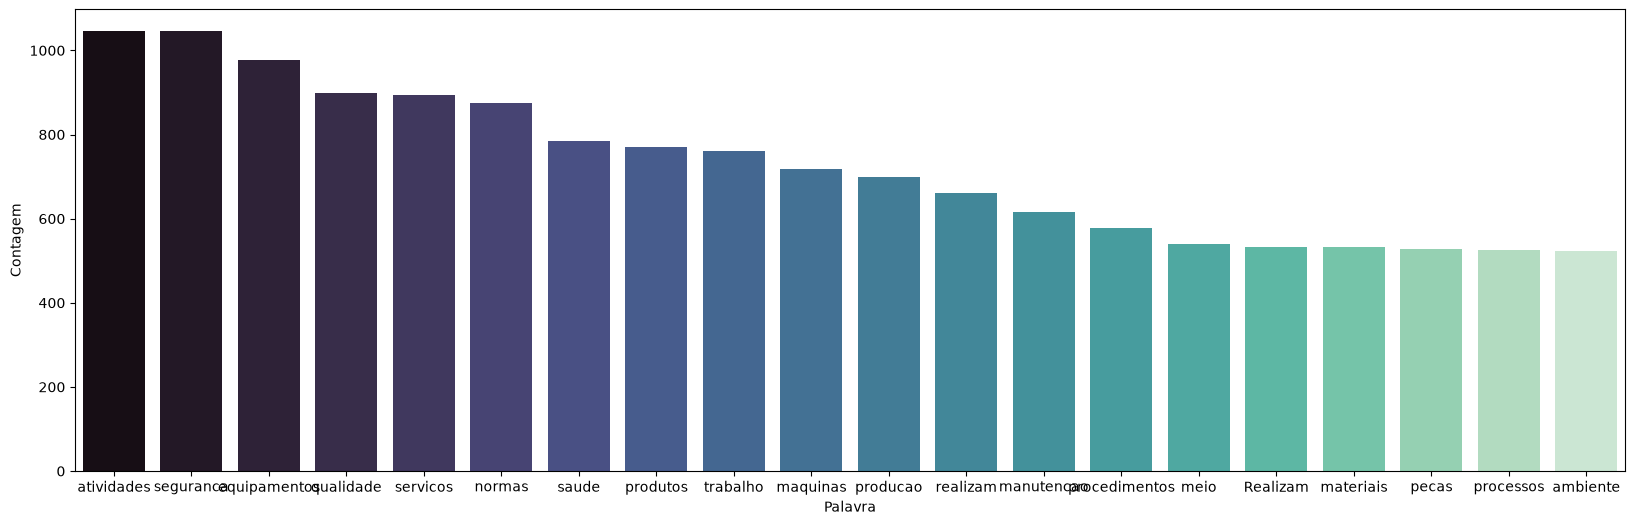

In [106]:
grafico_frequencia(df, 'tratamento_3', 20)

In [107]:
frase_processada =  []

for descricao in df['tratamento_3']:
  descricao = descricao.lower()
  palavras_texto = token_pontuacao.tokenize(descricao)
  nova_frase = [palavra for palavra in palavras_texto if palavra not in stopwords_sem_acento]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_4'] = frase_processada

In [108]:
classificar_texto(df, 'tratamento_4', 'tarefa')

Acurácia do modelo com 'tratamento_4': 72.89%


In [109]:
stemmer = nltk.RSLPStemmer()

In [110]:
frase_processada = []

for descricao in df['tratamento_4']:
  palavras_texto = token_pontuacao.tokenize(descricao)
  nova_frase = [stemmer.stem(palavra) for palavra in palavras_texto]
  frase_processada.append(' '.join(nova_frase))

df['tratamento_5'] = frase_processada

In [111]:
classificar_texto(df, 'tratamento_5', 'tarefa')

Acurácia do modelo com 'tratamento_5': 74.05%


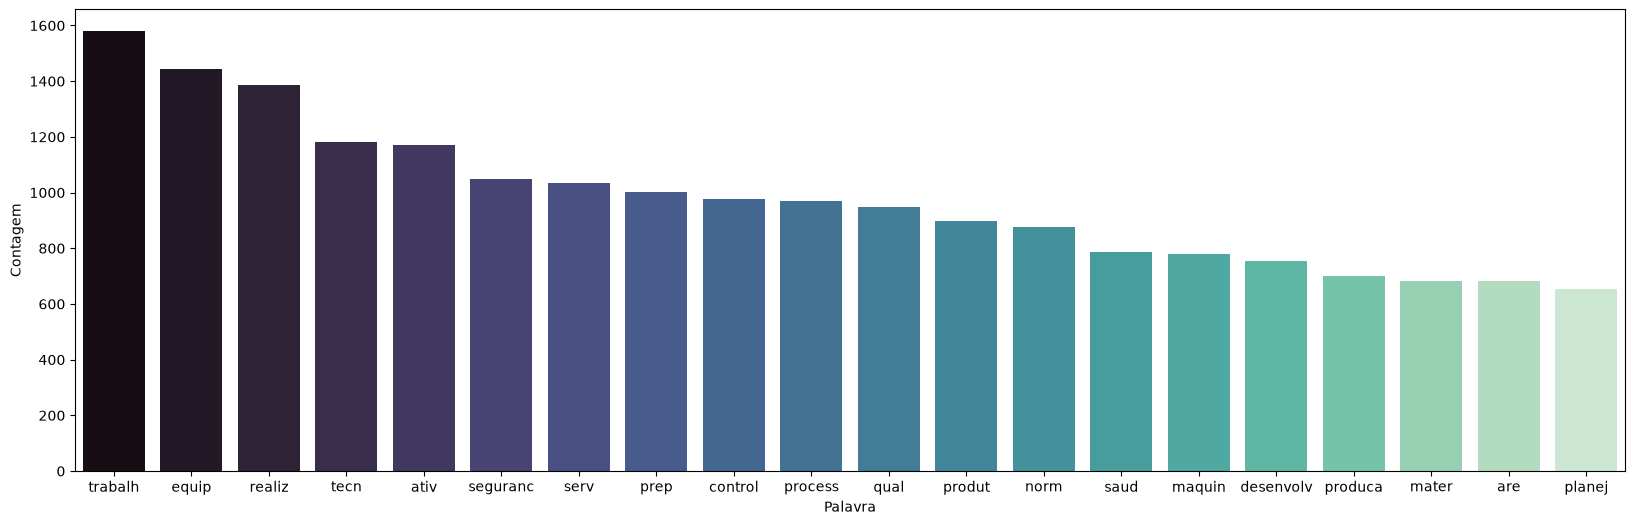

In [112]:
grafico_frequencia(df, 'tratamento_5', 20)

In [113]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(lowercase=False, max_features=50)

tfidf_bruto = tfidf.fit_transform(df["descricao"])
X_treino, X_teste, y_treino, y_teste = train_test_split(tfidf_bruto, df["tarefa"])
regressao_multinomial.fit(x_treino, y_treino)
acuracia_tfidf_bruto = regressao_multinomial.score(x_teste, y_teste)
print(f"Acurácia do modelo: {acuracia_tfidf_bruto *100:.2f}%")

Acurácia do modelo: 39.94%


In [114]:
tfidf_bruto = tfidf.fit_transform(df["descricao"])
X_treino, X_teste, y_treino, y_teste = train_test_split(tfidf_bruto, df["tarefa"])
regressao_multinomial.fit(x_treino, y_treino)
acuracia_tfidf_bruto = regressao_multinomial.score(x_teste, y_teste)
print(f"Acurácia do modelo: {acuracia_tfidf_bruto *100:.2f}%")

Acurácia do modelo: 39.94%


In [115]:
tfidf_tratados = tfidf.fit_transform(df['tratamento_5'])
X_treino, X_teste, y_treino, y_teste = train_test_split(tfidf_tratados, df['tarefa'])
regressao_multinomial.fit(X_treino, y_treino)
acuracia_tfidf_tratados = regressao_multinomial.score(X_teste, y_teste)
print(f'Acurácia do modelo: {acuracia_tfidf_tratados *100:.2f}%')

Acurácia do modelo: 74.64%


In [116]:
from nltk import ngrams

tfidf_50 = TfidfVectorizer(lowercase = False, max_features = 50, ngram_range=(1,2))
vetor_tfidf = tfidf_50.fit_transform(df['tratamento_5'])
x_treino, x_teste, y_treino, y_teste = train_test_split(vetor_tfidf, df['tarefa'])
regressao_multinomial.fit(x_treino, y_treino)
acuracia_tfidf_50 = regressao_multinomial.score(x_teste, y_teste)
print(f'Acuracia do modelo: {acuracia_tfidf_50 * 100:.2f}%')

Acuracia do modelo: 73.62%


In [117]:
tfidf_1000 = TfidfVectorizer(lowercase = False, max_features = 1000, ngram_range=(1,2))
vetor_tfidf = tfidf_1000.fit_transform(df['tratamento_5'])
x_treino, x_teste, y_treino, y_teste = train_test_split(vetor_tfidf, df['tarefa'], random_state=4979)
regressao_multinomial.fit(x_treino, y_treino)
acuracia_tfidf_1000 = regressao_multinomial.score(x_teste, y_teste)
print(f'Acuracia do modelo: {acuracia_tfidf_1000 * 100:.2f}%')

Acuracia do modelo: 92.57%


In [118]:
pesos = pd.DataFrame(
    regressao_multinomial.coef_[0].T,
    index=tfidf_1000.get_feature_names_out()
)

In [119]:
pesos.nlargest(20, 0)

,0
projet,2.497119
desenvolv,2.347795
gerenc,1.912534
sistem,1.576665
coorden,1.544775
pesquis,1.527348
recurs,1.420319
dirig,1.413669
conhec,1.317727
biolog,1.317355


In [120]:
pesos.nsmallest(10, 0)

,0
vend,-1.666739
control,-1.610486
local,-1.478831
prep,-1.471425
seguranc,-1.198532
norm seguranc,-1.184238
metal,-1.166277
veicul,-1.126114
pec,-1.121472
segu,-1.104669


In [121]:
def classificacao(posicao):

  sample_index = y_teste.index[posicao]
  print("=" * 50)
  print(f"Posição Original: {sample_index}")
  print("=" * 50)
  print(f"Titulo: {df.loc[sample_index, 'titulo']}")
  print("=" * 50)
  print(f"Descricao: {df.loc[sample_index, 'descricao']}")
  print("=" * 50)
  proba = regressao_multinomial.predict_proba(x_teste[posicao])
  print("=" * 50)
  print(f"Classes: {regressao_multinomial.classes_}")
  print("=" * 50)
  print(f"Probabilities: {proba}")
  print("=" * 50)

In [122]:
classificacao(1)

Posição Original: 1928
Titulo: 7661-20 Editor de texto e imagem - Arte-finalista; Diagramador (jornalismo) Dia- gramador e desenhista; Diagramador em terminal de vídeo; Especialista em arte final;  Montador de arte final.
Descricao: Planejam serviços da impressão gráfica e ajustam máquinas para impressão. Realizam serviços da impressão gráfica, tais como impressão plana e rotativa, impressão di- gital, flexografia, litografia, tipografia, letterset, calcografia, tampografia, rotogravura e serigrafia (silks-creen). Trabalham seguindo normas e procedimentos técnicos e de qualidade, segurança, meio ambiente, higiene e saúde.
Classes: ['Abstrata' 'Manual' 'R. Cognitiva' 'R. Manual']
Probabilities: [[0.03974132 0.05295071 0.01652854 0.89077943]]


Recalculando vetores de IF-IDF

In [123]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf_1000 = TfidfVectorizer(lowercase=False, max_features=1000, ngram_range=(1,2))
vetor_tfidf = tfidf_1000.fit_transform(df['tratamento_5'])
print("recalculado vetores de IF-IDF.")

recalculado vetores de IF-IDF.


In [124]:
from sklearn.model_selection import train_test_split

x_treino, x_teste, y_treino, y_teste = train_test_split(vetor_tfidf, df['tarefa'], random_state=4979)
print("Separação de teste e treino bem sucedida.")

Separação de teste e treino bem sucedida.


In [125]:
regressao_multinomial.fit(x_treino, y_treino)
print("Regressão logística multinomial treinada com sucesso.")

Regressão logística multinomial treinada com sucesso.


In [126]:
y_pred = regressao_multinomial.predict(x_teste)
print("Predições feitas com sucesso.")

Predições feitas com sucesso.


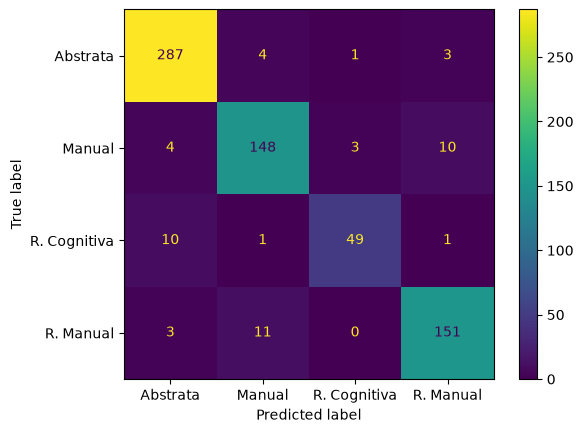

In [127]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay(confusion_matrix=confusion_matrix(y_teste, y_pred), display_labels=regressao_multinomial.classes_).plot()
plt.grid(False)
plt.show()

In [128]:
# Ocupações que foram confundidas

misclassified_indices = y_teste.index[y_teste != y_pred]

misclassified_titles = df.loc[misclassified_indices, 'titulo']
print("Classificados errados:")
display(misclassified_titles)

Classificados errados:


1865    7618-05 Inspetor de estamparia (produção têxti...
2374      9152-15 Luthier (restauração de cordas arcadas)
1150    4223-20 Operador de telemarketing técnico - Op...
1713    7252-15 Montador de máquinas operatrizes para ...
2026                      7772-05 Carpinteiro de carretas
2385    9501-10 Supervisor de manutenção eletromecânic...
929     3514-25 Oficial de justiça - Oficial judiciári...
1516       7112-45 Operador de trator (minas e pedreiras)
2373    9152-10 Reparador de instrumentos musicais - A...
868                      3253-05 Técnico em biotecnologia
945     3518-15 Papiloscopista policial - Datiloscopis...
985     3712-05 Colecionador de selos e moedas - Numis...
26                          0312-05 Cabo Bombeiro Militar
609                    2541-10 Técnico da receita federal
2350    9112-05 Mecânico de manutenção e instalação de...
869                    3253-10 Técnico em imunobiológicos
2312    8601-15 Supervisor de operação elétrica (geraç...
1147    4223-0

In [129]:
print(acuracia_tfidf_1000)

0.9256559766763849


In [130]:
def classificar_ifidf(random_state):
    tfidf_1000 = TfidfVectorizer(lowercase = False, max_features = 1000, ngram_range=(1,2))
    vetor_tfidf = tfidf_1000.fit_transform(df['tratamento_5'])
    x_treino, x_teste, y_treino, y_teste = train_test_split(vetor_tfidf, df['tarefa'], random_state=random_state)
    regressao_multinomial.fit(x_treino, y_treino)
    acuracia_tfidf_1000 = regressao_multinomial.score(x_teste, y_teste)

    return acuracia_tfidf_1000  
print(f'Acuracia do modelo: {acuracia_tfidf_1000 * 100:.2f}%')

Acuracia do modelo: 92.57%


In [131]:
for i in range(300):
    acuracia = classificar_ifidf(random_state=i)
    if acuracia > 0.95: 
        print(f"Random State: {i} - Acurácia: {acuracia * 100:.2f}% - Acurácia acima de 95%")

Random State: 1 - Acurácia: 95.19% - Acurácia acima de 95%
Random State: 4 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 9 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 76 - Acurácia: 95.63% - Acurácia acima de 95%
Random State: 97 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 106 - Acurácia: 95.19% - Acurácia acima de 95%
Random State: 109 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 127 - Acurácia: 95.19% - Acurácia acima de 95%
Random State: 142 - Acurácia: 95.34% - Acurácia acima de 95%
Random State: 165 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 172 - Acurácia: 95.34% - Acurácia acima de 95%
Random State: 198 - Acurácia: 95.34% - Acurácia acima de 95%
Random State: 230 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 261 - Acurácia: 95.04% - Acurácia acima de 95%
Random State: 265 - Acurácia: 95.19% - Acurácia acima de 95%
Random State: 291 - Acurácia: 95.92% - Acurácia acima de 95%


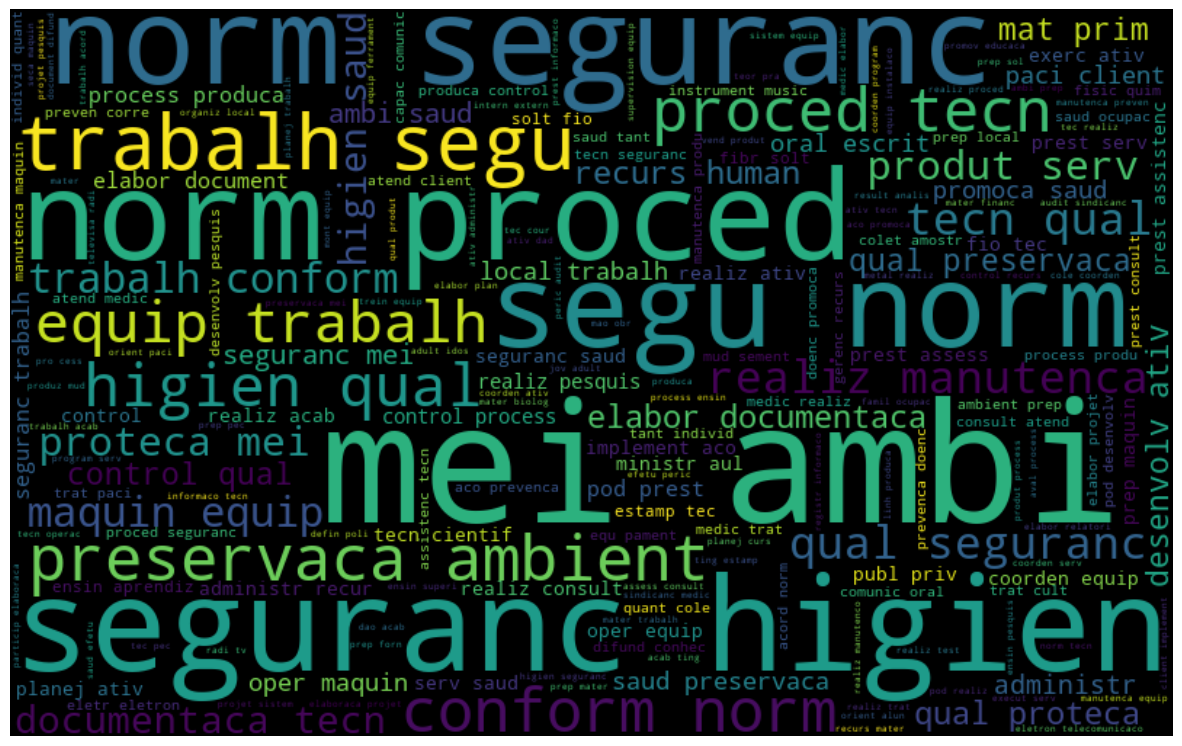

In [132]:
# Nuvem de palavras para tratamento_5
todas_palavras_tratamento5 = ' '.join([texto for texto in df.tratamento_5])

nuvem_tratamento5 = WordCloud(width=800, height=500, colormap='viridis')
nuvem_tratamento5.generate(todas_palavras_tratamento5)

plt.figure(figsize=(15, 10))
plt.imshow(nuvem_tratamento5, interpolation='bilinear')
plt.axis('off')
plt.show()

In [133]:
def agradação_das_tarefas(descricao):
    # 1. Preparar a descrição usando o mesmo pré-processamento
    nova_descricao = descricao
    # Aplicar o mesmo processamento (tratamento_5)
    nova_descricao_processada = processar_avaliacao(nova_descricao)

    # 2. Transformar com o TF-IDF treinado
    nova_descricao_tfidf = tfidf_1000.transform([nova_descricao_processada])

    # 3. Fazer a predição
    probabilidades = regressao_multinomial.predict_proba(nova_descricao_tfidf)
    previsao = regressao_multinomial.predict(nova_descricao_tfidf)

    # 4. Ver os resultados
    print(f"Ocupação prevista: {previsao[0]}")
    print(f"Confiança: {probabilidades[0].max() * 100:.2f}%")# Criar DataFrame com as probabilidades
    classes = regressao_multinomial.classes_
    probabilidades_dict = {classe: prob for classe, prob in zip(classes, probabilidades[0])}
    resultado_df = pd.DataFrame([probabilidades_dict]).T.sort_values(0, ascending=False)

    print("\nProbabilidades por ocupação:")
    print(resultado_df)

In [134]:
agradação_das_tarefas("Planejam a instalação e instalam produtos e acessórios em veículos e residências (alto falantes, amplificadores, geradores de áudio, alarmes, caixas acústicas, cortinas, persianas, portas sanfonadas, boxes), agendando a instalação, programando e executando o serviço. Realizam serviços de abertura de portas, conserto de fechaduras, modelagem, confecção e cópia de chaves. Atendem clientes, verificando perfil, levantando necessidades e apresentando alternativas de produtos e serviços. Reparam produtos, localizando defeitos e causas dos defeitos, substituindo, ajustando, limpando e lubrificando peças e componentes.")

Ocupação prevista: Manual
Confiança: 57.08%

Probabilidades por ocupação:
                     0
Manual        0.570828
Abstrata      0.173185
R. Cognitiva  0.146332
R. Manual     0.109655


In [135]:
desc = '''Comandam unidades de Polícia Militar e elaboram plano diretor da instituição. Planejam ações estratégicas, definem ações táticas e executam ações operacionais. Gerenciam atividades administrativas, administram recursos humanos e mantêm hierarquia e disciplina.'''

agradação_das_tarefas(desc)

Ocupação prevista: Abstrata
Confiança: 90.20%

Probabilidades por ocupação:
                     0
Abstrata      0.901981
Manual        0.056401
R. Manual     0.021640
R. Cognitiva  0.019978


In [136]:
dados_problema = pd.read_excel('C:\\Users\\ECO\\Desktop\\Mateus\\ITI_tratamento_dados\\Ocupações Problemáticas.xlsx', index_col=0)

In [137]:
dados_problema.head()

,Unnamed: 1,Unnamed: 2,2011,Unnamed: 4,Unnamed: 5,2012,Unnamed: 7,Unnamed: 8,2013,Unnamed: 10,...,Unnamed: 34,Unnamed: 35,2022,Unnamed: 37,Unnamed: 38,2023,Unnamed: 40,Unnamed: 41,2024,Unnamed: 43
2010,,,,,,,,,,,,,,,,,,,,,
Código CBO,Tipo de Erro,NaN,Código CBO,Tipo de Erro,NaN,Código CBO,Tipo de Erro,NaN,Código CBO,Tipo de Erro,...,Tipo de Erro,NaN,Código CBO,Tipo de Erro,NaN,Código CBO,Tipo de Erro,NaN,Código CBO,Tipo de Erro
214275,NaN,NaN,214275,NaN,NaN,214355,NaN,NaN,261720,NaN,...,NaN,NaN,261720,NaN,NaN,261720,NaN,NaN,261720,NaN
214355,NaN,NaN,214355,NaN,NaN,223410,NaN,NaN,261725,NaN,...,NaN,NaN,314605,NaN,NaN,314605,NaN,NaN,314605,NaN
223115,NaN,NaN,223101,NaN,NaN,253105,NaN,NaN,314605,NaN,...,NaN,NaN,322105,NaN,NaN,322105,NaN,NaN,322105,NaN
223410,NaN,NaN,223102,NaN,NaN,261720,NaN,NaN,322105,NaN,...,NaN,NaN,322115,NaN,NaN,322115,NaN,NaN,322115,NaN


In [138]:
# Agregação de tarefas para cada código em cada ano em `dados_problema`

# Anos disponíveis: 2010 está no índice e os demais anos em colunas numéricas
anos = [2010] + [int(c) for c in dados_problema.columns if isinstance(c, (int, float)) and pd.notna(c)]
anos = sorted(set(anos))

registros = []
for ano in anos:
    if ano == 2010:
        codigos = pd.Series(dados_problema.index, name='codigo')
    else:
        codigos = dados_problema[ano]

    for codigo in codigos:
        if pd.isna(codigo):
            continue

        codigo_str = str(codigo).strip()
        if not codigo_str or 'Cód' in codigo_str or 'Cod' in codigo_str:
            continue

        # Mantém apenas dígitos para padronizar o código CBO
        codigo_str = ''.join(ch for ch in codigo_str if ch.isdigit())
        if not codigo_str:
            continue

        registros.append({'ano': int(ano), 'codigo_cbo': codigo_str.zfill(6)})

dados_problema_longo = (
    pd.DataFrame(registros)
    .drop_duplicates()
    .sort_values(['ano', 'codigo_cbo'])
    .reset_index(drop=True)
)

# Mapeia tarefa a partir da base tratada
mapa_tarefa = df[['ocupacao', 'tarefa']].copy()
mapa_tarefa['ocupacao'] = (
    mapa_tarefa['ocupacao']
    .astype(str)
    .str.replace(r'\D', '', regex=True)
    .str.zfill(6)
)
mapa_tarefa = mapa_tarefa.drop_duplicates(subset='ocupacao')

dados_problema_tarefas = (
    dados_problema_longo
    .merge(mapa_tarefa, how='left', left_on='codigo_cbo', right_on='ocupacao')
    .drop(columns=['ocupacao'])
)
dados_problema_tarefas['tarefa'] = dados_problema_tarefas['tarefa'].fillna('Não encontrada')

# Agregação solicitada: quantidade por ano e tarefa
agregacao_tarefas_ano = (
    dados_problema_tarefas
    .groupby(['ano', 'tarefa'], as_index=False)
    .size()
    .rename(columns={'size': 'quantidade'})
    .sort_values(['ano', 'quantidade'], ascending=[True, False])
    .reset_index(drop=True)
)

display(dados_problema_tarefas.head(20))
display(agregacao_tarefas_ano)

,ano,codigo_cbo,tarefa
0,2010,214275,Não encontrada
1,2010,214355,Abstrata
2,2010,223115,Não encontrada
3,2010,223410,Abstrata
4,2010,253105,Abstrata
5,2010,261720,Abstrata
6,2010,261725,Abstrata
7,2010,314605,Abstrata
8,2010,322105,Abstrata
9,2010,322115,Abstrata


,ano,tarefa,quantidade
0,2010,Abstrata,19
1,2010,Não encontrada,13
2,2010,Manual,4
3,2010,R. Cognitiva,3
4,2010,R. Manual,1
...,...,...,...
70,2024,Abstrata,14
71,2024,Não encontrada,13
72,2024,Manual,3
73,2024,R. Cognitiva,1


In [139]:
dados_problema_tarefas.to_excel('dados_problema_tarefas.xlsx')

In [140]:
dados_problema_tarefas

,ano,codigo_cbo,tarefa
0,2010,214275,Não encontrada
1,2010,214355,Abstrata
2,2010,223115,Não encontrada
3,2010,223410,Abstrata
4,2010,253105,Abstrata
...,...,...,...
580,2024,521135,Não encontrada
581,2024,521140,Não encontrada
582,2024,524315,Não encontrada
583,2024,722225,R. Manual


In [141]:
dadosne = dados_problema_tarefas[dados_problema_tarefas['tarefa'] == 'Não encontrada']

In [142]:
dadosne

,ano,codigo_cbo,tarefa
0,2010,214275,Não encontrada
2,2010,223115,Não encontrada
23,2010,376405,Não encontrada
24,2010,376410,Não encontrada
25,2010,376415,Não encontrada
...,...,...,...
579,2024,521130,Não encontrada
580,2024,521135,Não encontrada
581,2024,521140,Não encontrada
582,2024,524315,Não encontrada


In [143]:
agradação_das_tarefas('Posam para fotógrafos e artistas plásticos imobilizando o corpo segundo orientação artística ou criando poses próprias, em estúdios, escolas de arte e locações internas ou externas; mostram produtos em trabalhos publicitários (fotos, filmes e eventos) mobilizando habilidades expressivas que atraem o olhar, que sugerem comportamentos e estilos de vida e que representam o tipo de pessoa que se quer associar ao produto; desfilam em passarelas ou em espaços determinados, onde sincronizam movimentos conforme a música e a coreografia, adotando expressão facial e corporal pré-estabelecida, para expor coleções de moda, detalhes do produto e acessórios, em “show e show room” de moda; cuidam da aparência e concentram-se na linguagem corporal.')

Ocupação prevista: R. Cognitiva
Confiança: 51.88%

Probabilidades por ocupação:
                     0
R. Cognitiva  0.518838
Abstrata      0.205378
Manual        0.155196
R. Manual     0.120588


In [144]:
dadosne['codigo_cbo'].unique()
len(dadosne['codigo_cbo'].unique())

81

In [145]:
df

,titulo,descricao,ocupacao,tarefa,tratamento_1,tratamento_2,tratamento_3,tratamento_4,tratamento_5
0,0101-05 Oficial General da Aeronáutica - Briga...,"As funções deste grupo consistem em manter, cu...",10105,Abstrata,"As funções deste grupo consistem manter, cumpr...",As funções deste grupo consistem manter cumpri...,As funcoes deste grupo consistem manter cumpri...,funcoes deste grupo consistem manter cumprir d...,funco dest grup consist mant cumpr defend cons...
1,0101-10 Oficial General do Exército - General-...,"As funções deste grupo consistem em manter, cu...",10110,Abstrata,"As funções deste grupo consistem manter, cumpr...",As funções deste grupo consistem manter cumpri...,As funcoes deste grupo consistem manter cumpri...,funcoes deste grupo consistem manter cumprir d...,funco dest grup consist mant cumpr defend cons...
2,0101-15 Oficial General da Marinha - Almirante...,"As funções deste grupo consistem em manter, cu...",10115,Abstrata,"As funções deste grupo consistem manter, cumpr...",As funções deste grupo consistem manter cumpri...,As funcoes deste grupo consistem manter cumpri...,funcoes deste grupo consistem manter cumprir d...,funco dest grup consist mant cumpr defend cons...
3,0102-05 Oficial da Aeronáutica - Capitão; Coro...,Estão compreendidas nesta família ocupacional ...,10205,Abstrata,Estão compreendidas nesta família ocupacional ...,Estão compreendidas nesta família ocupacional ...,Estao compreendidas nesta familia ocupacional ...,compreendidas nesta familia ocupacional pessoa...,compreend nest famil ocupac pesso serv volunta...
4,0102-10 Oficial do Exército - Capitão; Coronel...,Estão compreendidas nesta família ocupacional ...,10210,Abstrata,Estão compreendidas nesta família ocupacional ...,Estão compreendidas nesta família ocupacional ...,Estao compreendidas nesta familia ocupacional ...,compreendidas nesta familia ocupacional pessoa...,compreend nest famil ocupac pesso serv volunta...
...,...,...,...,...,...,...,...,...,...
2736,Artesão rendeiro,Os profissionais desta família ocupacional cri...,791160,R. Manual,Os profissionais desta família ocupacional cri...,Os profissionais desta família ocupacional cri...,Os profissionais desta familia ocupacional cri...,profissionais desta familia ocupacional criam ...,profiss dest famil ocupac cri confeccion produ...
2737,Operador de abastecimento de combustível de ae...,"Captam águas subterrâneas e superficiais, regi...",862160,R. Manual,"Captam águas subterrâneas superficiais, regist...",Captam águas subterrâneas superficiais registr...,Captam aguas subterraneas superficiais registr...,captam aguas subterraneas superficiais registr...,capt agu subterrane superfic registr control n...
2738,Vulcanizador de correias transportadoras,Planejam e realizam a manutenção de motores e ...,913125,R. Manual,Planejam realizam manutenção motores equipamen...,Planejam realizam manutenção motores equipamen...,Planejam realizam manutencao motores equipamen...,planejam realizam manutencao motores equipamen...,planej realiz manutenca motor equip mecan nava...
2739,Monitor de sistemas eletrônicos de segurança i...,"Instalam elevadores, escadas rolantes, portas ...",951315,Manual,"Instalam elevadores, escadas rolantes, portas ...",Instalam elevadores escadas rolantes portas po...,Instalam elevadores escadas rolantes portas po...,instalam elevadores escadas rolantes portas po...,instal elev esc rol port porto automa organiz ...


In [146]:
agradação_das_tarefas('Operam equipamentos de uma emissora de rádio; organizam e executam a programação da emissora; editam áudio (trilhas sonoras, músicas, vinhetas, comerciais, chamadas promocionais e programas) e mixam aúdio. No exercício das atividades mobilizam capacidades de administrar o tempo e de improvisar, além de capacidades comunicativas para interagir com as equipes técnica, de programação e comercial.')


Ocupação prevista: Abstrata
Confiança: 62.89%

Probabilidades por ocupação:
                     0
Abstrata      0.628890
Manual        0.157903
R. Manual     0.116731
R. Cognitiva  0.096476


In [147]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Ajuste o caminho se necessário
df = pd.read_csv('dados_tratados.csv')

# mesmo random_state usado no notebook
X = df[['descricao','tarefa']]
X_train, X_test, y_train, y_test = train_test_split(X, df['tarefa'], random_state=4979)

train = X_train.reset_index(drop=True)

# contagem por ocupação no treino
print(train['tarefa'].value_counts())

# mostrar 3 exemplos de descrição por ocupação
for tarefa in train['tarefa'].unique():
    print(f"\n=== {tarefa} ===")
    print(train[train['tarefa'] == tarefa]['descricao'].head(3).to_string(index=False))

# opcional: salvar CSV com o split de treino
train.to_csv('dados_treino_split.csv', index=False)
print('\\nSalvo em dados_treino_split.csv')

tarefa
Abstrata        853
Manual          519
R. Manual       494
R. Cognitiva    189
Name: count, dtype: int64

=== Abstrata ===
Desenvolvem cartela e implementam receitas de c...
Interpretam as especificações médicas e efetuam...
Inspecionam o recebimento e organizam o armazen...

=== R. Cognitiva ===
Administram e controlam a frota de veículos no ...
Organizam a rotina de serviços e realizam entra...
Apontam a produção e controlam a frequência de ...

=== Manual ===
Extraem gomas elásticas, não elásticas e resina...
Manejam a criação extensiva e confinada de suín...
Supervisionam equipes de trabalho na produção e...

=== R. Manual ===
Realizam manutenção de equipamentos, montagem e...
Organizam área de trabalho para acabamento, tin...
Os profissionais desta família ocupacional cria...
\nSalvo em dados_treino_split.csv


In [148]:
#5211
agradação_das_tarefas('Planejam a instalação e instalam produtos e acessórios em veículos e residências (alto-falantes, amplificadores, geradores de áudio, alarmes, caixas acústicas, cortinas, persianas, portas sanfonadas, boxes), agendando a instalação, programando e executando o serviço. Realizam serviços de abertura de portas, conserto de fechaduras, modelagem, confecção e cópia de chaves. Atendem clientes, verificando perfil, levantando necessidades e apresentando alternativas de produtos e serviços. Reparam produtos, localizando defeitos e causas dos defeitos, substituindo, ajustando, limpando e lubrificando peças e componentes.')

Ocupação prevista: Manual
Confiança: 57.08%

Probabilidades por ocupação:
                     0
Manual        0.570828
Abstrata      0.173185
R. Cognitiva  0.146332
R. Manual     0.109655


In [149]:
dados_treino_split = pd.read_csv('dados_treino_split.csv')
dados_treino_split

,descricao,tarefa
0,Desenvolvem cartela e implementam receitas de ...,Abstrata
1,Interpretam as especificações médicas e efetua...,Abstrata
2,Inspecionam o recebimento e organizam o armaze...,Abstrata
3,Administram fundos e carteiras de investimento...,Abstrata
4,Administram e controlam a frota de veículos no...,R. Cognitiva
...,...,...
2050,Realizam tratos culturais em fruticultura; pre...,Manual
2051,Operam equipamentos de perfuração e de corte d...,Manual
2052,"Planejam, coordenam, orientam e supervisionam ...",Abstrata
2053,"Recebem folhas de fumo, inspecionando, identif...",R. Manual
